# MNIST Digit Classifier (simple ANN)

The "hello world" of image classification: recognise handwritten digits (0-9) from 28x28 grayscale images
(60,000 training / 10,000 test images).

**Pipeline:** load data -> scale pixels to [0, 1] -> flatten 28x28 to 784 -> single `Dense` layer -> train -> evaluate -> confusion matrix.

The confusion matrix shows *which* digits get mixed up (rows = truth, columns = prediction).

C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8802 - loss: 0.4638
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9154 - loss: 0.3029
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9206 - loss: 0.2834
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9242 - loss: 0.2726
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9260 - loss: 0.2666
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9261 - loss: 0.2667
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


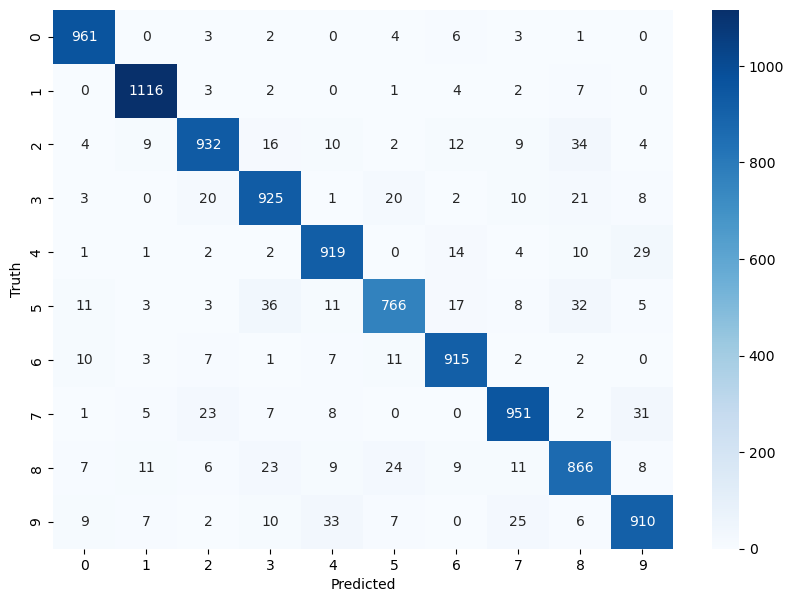

In [1]:
# Baseline ANN on MNIST using a single dense layer.
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Load Data
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# 2. Scaling of the image
X_train = X_train / 255.0
X_test = X_test / 255.0

# 3. Flattening (FIXED: Yahan pehle X_train likha hua tha dono jagah)
# flatten each 28x28 image into a 784-long vector (dense layers need 1-D input)
X_train_flattened = X_train.reshape(len(X_train), 28*28)
X_test_flattened = X_test.reshape(len(X_test), 28*28)

# 4. Simple neural Network
model = keras.Sequential([
    # 10 outputs = one per digit (sigmoid here; softmax is the more common choice for multi-class)
    keras.layers.Dense(10, input_shape=(784,), activation='sigmoid')
])

# sparse_categorical_crossentropy: labels are integers 0-9, not one-hot vectors
model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

# Train Model
model.fit(X_train_flattened, y_train, epochs=5)

# 5. Evaluation (Ab yeh bina kisi error ke chalega)
model.evaluate(X_test_flattened, y_test)

# 6. Prediction & Confusion Matrix
y_predicted = model.predict(X_test_flattened)
# argmax converts the 10 output scores into one predicted digit
y_predicted_labels = [np.argmax(i) for i in y_predicted]

# Generate Confusion Matrix
# confusion matrix: the diagonal holds the correct predictions
